<a href="https://colab.research.google.com/github/Lakshmi1477/Recurring_Drift_Research/blob/main/Recurring_Concept_Drift_Pilot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

River version: 0.23.0
NumPy version: 2.1.3
Pandas version: 2.2.3
Research environment is ready!
Dataset shape: (9000, 5)

Concept distribution:
concept
A    3000
B    3000
C    3000
Name: count, dtype: int64

Drift points: [1500, 3000, 4500, 6000, 7500] | recurring concept? [False, False, True, True, True]
Total label budget: 900 of 9000 (10%)

First five rows:
         x1        x2        x3  label concept
0  7.739560  4.388784  8.585979      0       A
1  6.973680  0.941773  9.756224      0       A
2  7.611397  7.860643  1.281136      1       A
3  4.503859  3.707980  9.267650      1       A
4  6.438651  8.227616  4.434142      1       A


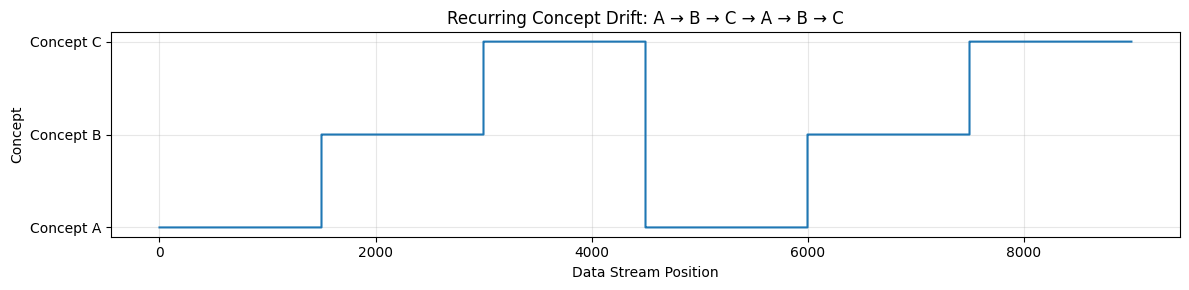

Fixed-budget baseline results
--------------------------------
Total samples: 9000
Labels queried: 900
Actual label rate: 10.0 %
Accuracy on ALL samples: 0.8032
Accuracy on queried labels only (old metric): 0.8
Finished 20 seeds in 16s | stream length 9000 | budget 900 labels | drifts at [1500, 3000, 4500, 6000, 7500] | recurring [False, False, True, True, True]

Summary (mean over seeds):
                               acc_all  acc_std  labels  acc_post_drift  acc_post_novel  acc_post_recurring  labels_post_novel  labels_post_recurring  detections  false_alarms  mean_delay  missed
strategy                                                                                                                                                                                           
Full labels (upper bound)        0.906    0.003  9000.0           0.821           0.825               0.819            300.000                300.000        0.00           NaN         NaN     NaN
Random fixed       

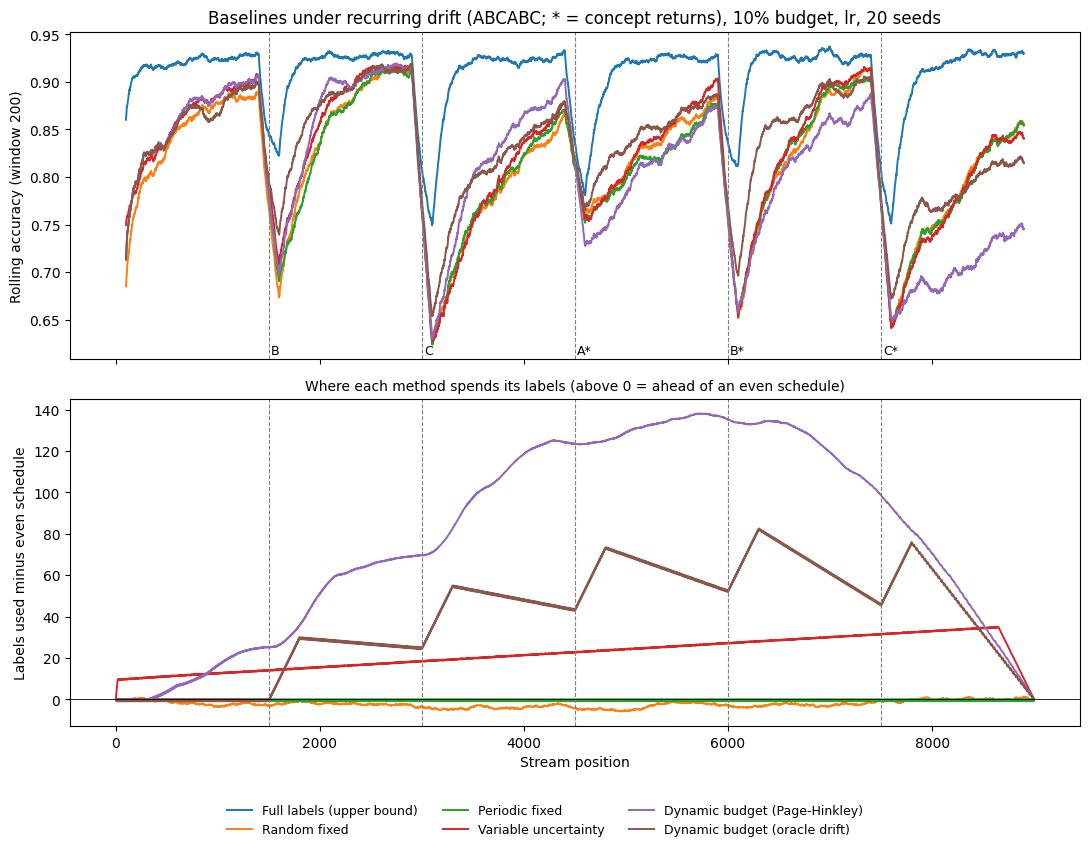


Saved to ./results/ : summary.csv, per_seed_results.csv, baselines.png, stream_concepts.png


In [7]:

# # 1. Environment

# %%
# %pip install -q "river>=0.22,<0.24" numpy pandas matplotlib scikit-learn scipy
import copy
import itertools
import os
import pickle
import time
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import river
from river import drift, linear_model, naive_bayes, optim, preprocessing, tree
from scipy.stats import wilcoxon

print("River version:", river.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Research environment is ready!")

# %% [markdown]
# # 2. Settings

# %%
SEGMENT_SIZE = 1500                 # instances per concept segment
CONCEPT_SEQUENCE = list("ABCABC")   # later appearances are RECURRING concepts
NOISE = 0.05                        # label noise
BUDGET_RATE = 0.10                  # main experiment: label budget / stream length
BUDGET_SWEEP = [0.05, 0.10, 0.20]   # label-efficiency experiment
EVAL_SEEDS = list(range(100, 120))  # evaluation seeds
DEV_SEEDS = list(range(200, 208))   # tuning seeds (proposed method only)
CLASSIFIER = "lr"                   # "lr" | "hat" | "ht" | "gnb"
POST_DRIFT_WINDOW = 300             # instances after a drift for recovery metrics
DEMO_SEED = 42
RUN_TUNING = False                  # grid search for the proposed method (slow)
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

# %% [markdown]
# # 3. Recurring-drift stream (SEA-style concepts)

# %%
def generate_sea_segment(n, concept, rng, noise=NOISE):
    """One concept segment: 3 features in [0, 10]."""
    X = rng.random((n, 3)) * 10
    if concept == "A":
        y = ((X[:, 0] + X[:, 1]) > 8).astype(int)
    elif concept == "B":      # shifted boundary (strong drift from A)
        y = ((X[:, 0] + X[:, 1]) > 12).astype(int)
    elif concept == "C":      # different feature pair
        y = ((X[:, 1] + X[:, 2]) > 9).astype(int)
    else:
        raise ValueError(f"unknown concept {concept}")
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y


def make_stream(sequence, segment_size, seed, noise=NOISE):
    """Returns X, y, concept_per_instance, change_points, recurring_flags.
    recurring[k] is True if the concept entered at change point k appeared before."""
    rng = np.random.default_rng(seed)
    X_parts, y_parts, concepts = [], [], []
    for concept in sequence:
        Xp, yp = generate_sea_segment(segment_size, concept, rng, noise)
        X_parts.append(Xp)
        y_parts.append(yp)
        concepts.extend([concept] * segment_size)
    change_points, recurring = [], []
    for k in range(1, len(sequence)):
        if sequence[k] != sequence[k - 1]:
            change_points.append(k * segment_size)
            recurring.append(sequence[k] in sequence[:k])
    return np.vstack(X_parts), np.concatenate(y_parts), concepts, change_points, recurring


X, y, concepts, change_points, recurring = make_stream(CONCEPT_SEQUENCE, SEGMENT_SIZE, DEMO_SEED)
N = len(X)
data = pd.DataFrame(X, columns=["x1", "x2", "x3"])
data["label"] = y
data["concept"] = concepts
print("Dataset shape:", data.shape)
print(data["concept"].value_counts().to_string())
print("Drift points:", change_points, "| recurring concept?", recurring)

concept_to_number = {c: i for i, c in enumerate(sorted(set(CONCEPT_SEQUENCE)))}
plt.figure(figsize=(12, 3))
plt.plot(np.arange(N), data["concept"].map(concept_to_number), drawstyle="steps-post")
plt.xlabel("Data Stream Position")
plt.ylabel("Concept")
plt.title("Recurring Concept Drift: " + " → ".join(CONCEPT_SEQUENCE))
plt.yticks(list(concept_to_number.values()), [f"Concept {c}" for c in concept_to_number])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "stream_concepts.png"), dpi=140)
plt.show()

# %% [markdown]
# # 4. Base classifier and the strategy interface

# %%
def make_model(name=None):
    """Base learner. It must be able to forget, otherwise drift is invisible."""
    name = name or CLASSIFIER          # global setting, read at call time
    if name == "lr":
        return preprocessing.StandardScaler() | linear_model.LogisticRegression(
            optimizer=optim.SGD(0.05), intercept_lr=0.1)
    if name == "hat":
        return tree.HoeffdingAdaptiveTreeClassifier(seed=0)
    if name == "ht":
        return tree.HoeffdingTreeClassifier()
    if name == "gnb":
        return naive_bayes.GaussianNB()
    raise ValueError(f"unknown classifier {name}")


class Strategy:
    """Decides which labels to request. Interface used by run_stream():
       observe(x)                         every instance (unlabelled information)
       model_for_prediction(default)      model used to predict instance t
       query(t, proba)                    True if the label of instance t is requested
       handle_label(t, x, y, correct, m)  called when a label is bought (learns from it)
    """
    name = "base"

    def __init__(self, n, rate, seed, change_points=()):
        self.n, self.rate = n, rate
        self.cap = int(round(n * rate))              # hard cap on total labels
        self.rng = np.random.default_rng(seed)
        self.spent = 0
        self.change_points = set(change_points)
        self.detections = []
        self.self_n, self.self_ok = 0, 0          # self-labelled instances (no label bought)

    def observe(self, x):
        pass

    def unlabeled(self, t, x, proba, model, y_diag):
        """Called for instances whose label was NOT bought. y_diag is the true label and is
        for diagnostics ONLY (pseudo-label precision); strategies must not use it."""
        pass

    def model_for_prediction(self, default):
        return default

    def query(self, t, proba):
        raise NotImplementedError

    def handle_label(self, t, x, y, correct, model):
        model.learn_one(x, y)
        self.spent += 1
        self.feedback(t, correct)

    def feedback(self, t, correct):
        pass


def new_detector(kind):
    if kind == "adwin":
        return drift.ADWIN(delta=0.002)
    return drift.PageHinkley(min_instances=30, delta=0.005, threshold=5, alpha=0.99)


# %% [markdown]
# # 5. Baselines

# %%
class FullLabels(Strategy):
    name = "Full labels (upper bound)"

    def __init__(self, n, rate, seed, change_points=()):
        super().__init__(n, 1.0, seed, change_points)

    def query(self, t, proba):
        return True


class RandomFixed(Strategy):
    name = "Random fixed"

    def __init__(self, n, rate, seed, change_points=()):
        super().__init__(n, rate, seed, change_points)
        self.mask = np.zeros(n, dtype=bool)
        self.mask[self.rng.choice(n, self.cap, replace=False)] = True

    def query(self, t, proba):
        return bool(self.mask[t])


class PeriodicFixed(Strategy):
    name = "Periodic fixed"

    def query(self, t, proba):
        return int((t + 1) * self.rate) > int(t * self.rate)


class VarUncertainty(Strategy):
    """Variable uncertainty with randomisation (Zliobaite et al., 2014)."""
    name = "Variable uncertainty"

    def __init__(self, n, rate, seed, change_points=(), s=0.01, delta=1.0, w=100):
        super().__init__(n, rate, seed, change_points)
        self.s, self.delta, self.w = s, delta, w
        self.theta, self.u = 1.0, 0.0

    def query(self, t, proba):
        ask = False
        if self.spent < self.cap and self.u < self.rate:
            maxp = max(proba.values()) if proba else 0.0
            thr = self.theta * self.rng.normal(1.0, self.delta)
            ask = maxp < thr
            self.theta *= (1 - self.s) if ask else (1 + self.s)
        self.u = (self.u * (self.w - 1) + float(ask)) / self.w
        return ask


class DynamicBudget(Strategy):
    """Drift-dependent budget (recurrence-BLIND), in the style of Castellani et al.
    (2022) / Aguiar & Cano (2024): the remaining budget is spread evenly; after a
    drift signal labels are requested at `boost_rate` for `boost_len` instances; the
    total stays at the common budget. Every drift gets the same boost.
    detector: "ph" (Page-Hinkley on errors of labelled instances) or "oracle"."""

    def __init__(self, n, rate, seed, change_points=(), detector="ph",
                 boost_rate=0.2, boost_len=300, reserve_frac=0.25):
        super().__init__(n, rate, seed, change_points)
        self.boost_rate, self.boost_len, self.reserve_frac = boost_rate, boost_len, reserve_frac
        self.boost_until, self.credit = -1, 0.0
        self.oracle = detector == "oracle"
        self.det = None if self.oracle else new_detector(detector)
        self.name = ("Dynamic budget (oracle drift)" if self.oracle
                     else "Dynamic budget (Page-Hinkley)")

    def query(self, t, proba):
        if self.oracle and t in self.change_points:
            self.boost_until = t + self.boost_len
            self.detections.append(t)
        remaining = self.cap - self.spent
        left = max(self.n - t, 1)
        boosting = t < self.boost_until and remaining > self.reserve_frac * self.rate * left
        self.credit += self.boost_rate if boosting else remaining / left
        if self.credit >= 1.0:
            self.credit -= 1.0
            return remaining > 0
        return False

    def feedback(self, t, correct):
        if self.det is not None:
            self.det.update(0.0 if correct else 1.0)
            if self.det.drift_detected:
                self.boost_until = t + self.boost_len
                self.detections.append(t)


# %% [markdown]
# # 6. PROPOSED METHOD: concept memory + recurrence check + novelty-based budget
#
# 1. **Drift detection** (same Page-Hinkley detector as the dynamic baseline).
# 2. **Concept memory**: snapshots of the learner for concepts the stream has left.
#    A snapshot is taken every `snapshot_every` instances; when a drift is detected,
#    the snapshot taken at least `margin` instances earlier (before the change, which
#    is only detected after a delay) is stored, unless an almost identical concept is
#    already stored (prediction agreement >= 0.9 on recent unlabelled instances).
# 3. **Recurrence check**: after a detection, `probe_k` labels are bought. The stored
#    models and the current model are scored on these labels (the current model is not
#    trained during the probe). Outcome:
#       - current model still accurate (>= tau)      -> "same" (false alarm)
#       - a stored model accurate (>= tau)           -> "recurring": reload it
#       - otherwise                                  -> "novel"
# 4. **Budget policy**: novel concept -> large boost, recurring -> small boost,
#    false alarm -> no boost. The remaining budget is re-spread afterwards, so labels
#    saved on returning concepts go back to the shared pool and the total stays fixed.

# %%
class RecurrenceAwareBudget(Strategy):
    def __init__(self, n, rate, seed, change_points=(), detector="ph", aware=True,
                 probe_k=24, probe_rate=0.5, tau=0.70,
                 novel_boost=(0.40, 300), recur_boost=(0.20, 100), uniform_boost=(0.15, 300),
                 reserve_frac=0.25, snapshot_every=100, margin=300, mem_cap=10,
                 win_len=15, switch_margin=0.15):
        super().__init__(n, rate, seed, change_points)
        self.model = make_model()
        self.win_len, self.switch_margin = win_len, switch_margin
        self.win_cur = deque(maxlen=win_len)       # recent correctness of current model
        self.win_mem = []                          # same, for every stored model
        self.recent_lab = deque(maxlen=win_len)    # recent labelled (x, y) pairs
        self.aware = aware
        self.probe_k, self.probe_rate, self.tau = probe_k, probe_rate, tau
        self.novel_boost, self.recur_boost, self.uniform_boost = novel_boost, recur_boost, uniform_boost
        self.reserve_frac = reserve_frac
        self.snapshot_every, self.margin, self.mem_cap = snapshot_every, margin, mem_cap
        self.oracle = detector == "oracle"
        self.det = None if self.oracle else new_detector(detector)
        self.phase, self.probe, self.pending, self.det_time = "normal", [], None, 0
        self.credit, self.boost_rate, self.boost_until = 0.0, 0.0, -1
        self.memory, self.snaps = [], deque(maxlen=10)
        self.recent_x = deque(maxlen=200)
        self.decisions = []                     # (detection time, outcome)
        self._t = -1
        if self.oracle and aware:
            self.name = "Proposed (oracle drift)"
        elif self.oracle:
            self.name = "Ablation: memory + uniform boost (oracle drift)"
        elif aware:
            self.name = "Proposed: recurrence-aware budget"
        else:
            self.name = "Ablation: memory + uniform boost"

    # ---- helpers -----------------------------------------------------------
    def observe(self, x):
        self._t += 1
        self.recent_x.append(x)
        if self.phase == "normal" and self._t % self.snapshot_every == 0:
            self.snaps.append((self._t, copy.deepcopy(self.model)))

    def model_for_prediction(self, default):
        return self.model

    @staticmethod
    def _predict(m, x):
        p = m.predict_one(x)
        return 0 if p is None else int(p)

    def _acc(self, m):
        return float(np.mean([self._predict(m, x) == yy for x, yy in self.probe]))

    def _reset_windows(self):
        self.win_cur.clear()
        self.win_mem = [deque(maxlen=self.win_len) for _ in self.memory]

    def _remember(self, snapshot):
        xs = list(self.recent_x)[-100:]
        for i, m in enumerate(self.memory):
            agree = np.mean([self._predict(snapshot, x) == self._predict(m, x) for x in xs])
            if agree >= 0.9:                     # same concept already stored: refresh it
                self.memory[i] = snapshot
                self._reset_windows()
                return
        self.memory.append(snapshot)
        if len(self.memory) > self.mem_cap:
            self.memory.pop(0)
        self._reset_windows()

    def _set_boost(self, t, outcome):
        if not self.aware:
            rate, length = self.uniform_boost
        elif outcome == "same":
            rate, length = 0.0, 0
        elif outcome == "recurring":
            rate, length = self.recur_boost
        else:
            rate, length = self.novel_boost
        self.boost_rate, self.boost_until = rate, t + length

    def _pending_snapshot(self, t):
        old = [m for (ts, m) in self.snaps if ts <= t - self.margin]
        return old[-1] if old else None            # model of the concept being left

    def _switch_to_memory(self, t, best):
        """Continuous recurrence check fired: a stored model fits the latest labels
        clearly better than the current one -> reload it (no extra labels needed)."""
        self.detections.append(t)
        pend = self._pending_snapshot(t)
        self.model = copy.deepcopy(self.memory[best])
        if pend is not None:
            self._remember(pend)
        for x, yy in self.recent_lab:              # fine-tune on the labels just seen
            self.model.learn_one(x, yy)
        self._set_boost(t, "recurring")
        self.decisions.append((t, "recurring"))
        self._reset_windows()

    # ---- detection -> probe -> decision -------------------------------------
    def _on_detection(self, t):
        self.detections.append(t)
        self.det_time = t
        self.pending = self._pending_snapshot(t)
        self.phase, self.probe, self.credit = "probe", [], 0.0

    def _decide(self, t):
        a_cur = self._acc(self.model)
        mem_acc = [self._acc(m) for m in self.memory]
        best = int(np.argmax(mem_acc)) if mem_acc else -1
        if best >= 0 and mem_acc[best] >= self.tau and mem_acc[best] > a_cur:
            outcome = "recurring"
            self.model = copy.deepcopy(self.memory[best])
        elif a_cur >= self.tau:
            outcome = "same"
        else:
            outcome = "novel"
        if outcome != "same" and self.pending is not None:
            self._remember(self.pending)
        self._set_boost(t, outcome)
        for x, yy in self.probe:                  # now learn from the probe labels
            self.model.learn_one(x, yy)
        self.decisions.append((self.det_time, outcome))
        self._reset_windows()
        self.phase = "normal"

    # ---- interface -----------------------------------------------------------
    def query(self, t, proba):
        if self.oracle and t in self.change_points and self.phase == "normal":
            self._on_detection(t)
        if self.phase == "probe":
            self.credit += self.probe_rate
        else:
            remaining = self.cap - self.spent
            left = max(self.n - t, 1)
            boosting = t < self.boost_until and remaining > self.reserve_frac * self.rate * left
            self.credit += self.boost_rate if boosting else remaining / left
        if self.credit >= 1.0:
            self.credit -= 1.0
            return (self.cap - self.spent) > 0
        return False

    def handle_label(self, t, x, y, correct, model):
        self.spent += 1
        if self.phase == "probe":
            self.probe.append((x, y))
            if len(self.probe) >= self.probe_k:
                self._decide(t)
            return
        # continuous recurrence check on labels that are bought anyway
        self.win_cur.append(correct)
        self.recent_lab.append((x, y))
        if self.memory:
            if len(self.win_mem) != len(self.memory):
                self._reset_windows()
            for w, m in zip(self.win_mem, self.memory):
                w.append(self._predict(m, x) == y)
        self.model.learn_one(x, y)
        if self.memory and len(self.win_cur) >= self.win_len:
            cur_a = float(np.mean(self.win_cur))
            mem_a = [float(np.mean(w)) if len(w) >= self.win_len else 0.0 for w in self.win_mem]
            best = int(np.argmax(mem_a))
            if mem_a[best] >= self.tau and mem_a[best] - cur_a >= self.switch_margin:
                self._switch_to_memory(t, best)
                return
        if self.det is not None:
            self.det.update(0.0 if correct else 1.0)
            if self.det.drift_detected:
                self._on_detection(t)


# %% [markdown]
# # 6b. NEW METHOD: Posterior-Guided Label Allocation (PGLA)
# Drift detection needs labels, but labels are scarce, so detectors fire late. PGLA
# removes the detector. It keeps a probability over WHICH stored concept is active (plus
# a "new concept" hypothesis, modelled as an uninformative expert), updates it with
# every purchased label (Bayes rule + fixed-share switching), and:
#   1. ALLOCATION: labelling rate = remaining-budget pace x a multiplier that grows with
#      the entropy of the posterior. A returning concept is confirmed after a few labels
#      (entropy falls, labels drop); a new concept is never confirmed (entropy stays high,
#      labels keep flowing) until a new concept model is spawned. Total budget stays fixed.
#   2. SELECTION: a due label is spent on an instance where the plausible concept models
#      disagree, because that label separates the hypotheses best.
#   3. REUSE: predictions use the posterior-weighted mixture of stored concept models;
#      only the most probable model learns from each label.
# Ablations: PGLA without allocation or selection ("posterior tracking, uniform labels",
# close in spirit to SELeCT-style continuous concept evaluation on a fixed label rate).

# %%
class _Mixture:
    """Adapter so run_stream can query the posterior-weighted mixture."""
    def __init__(self, owner):
        self.owner = owner

    def predict_proba_one(self, x):
        return self.owner.mixture_proba(x)


class PosteriorGuidedAllocation(Strategy):
    def __init__(self, n, rate, seed, change_points=(), allocate=True, select=True,
                 eps=0.05, alpha=0.005, m_lo=0.4, m_hi=3.0, delta=0.4,
                 spawn_thr=0.5, n_min=40, buf_len=15, mem_cap=10, p_new0=0.02, learn_thr=0.4, switch_thr=0.5):
        super().__init__(n, rate, seed, change_points)
        self.learn_thr, self.switch_thr = learn_thr, switch_thr
        self.allocate, self.select = allocate, select
        self.eps, self.alpha, self.m_lo, self.m_hi, self.delta = eps, alpha, m_lo, m_hi, delta
        self.spawn_thr, self.n_min, self.buf_len, self.mem_cap = spawn_thr, n_min, buf_len, mem_cap
        self.models = [make_model()]
        self.nlab = [0]
        self.pi = np.array([1.0 - p_new0, p_new0])      # K concept models + "new"
        self.active, self.credit, self.since_spawn = 0, 0.0, 10 ** 9
        self.buf = deque(maxlen=buf_len)
        self.recent_x = deque(maxlen=200)
        self.x = None
        self.decisions = []
        self._mix = _Mixture(self)
        if allocate and select:
            self.name = "PGLA: posterior-guided allocation"
        elif not allocate and not select:
            self.name = "Ablation: posterior tracking, uniform labels"
        else:
            self.name = "Ablation: allocation without instance selection"

    # ---- helpers -----------------------------------------------------------
    @staticmethod
    def _p1(m, x):
        pr = m.predict_proba_one(x)
        return float(pr.get(1, 0.0)) if pr else 0.5

    def _entropy_norm(self):
        p = self.pi[self.pi > 1e-12]
        return float(-(p * np.log(p)).sum() / np.log(len(self.pi)))

    def mixture_proba(self, x):
        K = len(self.models)
        w = self.pi[:K].copy()
        if w.sum() < 1e-9:
            w = np.zeros(K)
            w[self.active] = 1.0
        w = w / w.sum()
        p1 = float(sum(wk * self._p1(m, x) for wk, m in zip(w, self.models)))
        return {0: 1.0 - p1, 1: p1}

    def _informative(self, x):
        K = len(self.models)
        cand = [k for k in range(K) if self.pi[k] > 0.05 or k == self.active]
        if len(cand) < 2:
            return True
        ps = [self._p1(self.models[k], x) for k in cand]
        return (max(ps) - min(ps)) >= self.delta

    def _agree(self, a, b):
        xs = list(self.recent_x)[-100:]
        return float(np.mean([(self._p1(a, x) > 0.5) == (self._p1(b, x) > 0.5) for x in xs]))

    def _spawn(self, t):
        fresh = make_model()
        for x, y in self.buf:
            fresh.learn_one(x, y)
        for j, m in enumerate(self.models):         # already stored? then it is a return
            if self._agree(fresh, m) >= 0.9:
                self._set_active(j, t, "recurring")
                return
        self.models.append(fresh)
        self.nlab.append(len(self.buf))
        if len(self.models) > self.mem_cap:
            drop = int(np.argmin(self.pi[:len(self.models) - 1]))
            if drop == self.active:
                drop = (drop + 1) % (len(self.models) - 1)
            self.models.pop(drop)
            self.nlab.pop(drop)
        K = len(self.models)
        self.pi = np.full(K + 1, 0.08 / K)
        self.active = K - 1
        self.pi[self.active] = 0.9
        self.pi[K] = 0.02
        self.pi /= self.pi.sum()
        self.since_spawn = 0
        self.detections.append(t)
        self.decisions.append((t, "novel"))

    def _set_active(self, j, t, outcome):
        if j != self.active:
            self.active = j
            self.detections.append(t)
            self.decisions.append((t, outcome))

    # ---- interface -----------------------------------------------------------
    def observe(self, x):
        self.x = x
        self.recent_x.append(x)

    def model_for_prediction(self, default):
        return self._mix

    def query(self, t, proba):
        remaining = self.cap - self.spent
        left = max(self.n - t, 1)
        K = len(self.models)
        self.pi = (1 - self.alpha) * self.pi + self.alpha / (K + 1)       # fixed-share switching
        mult = (self.m_lo + (self.m_hi - self.m_lo) * self._entropy_norm()) if self.allocate else 1.0
        self.credit += (remaining / left) * mult
        if self.credit >= 1.0 and remaining > 0:
            if (not self.select) or self.credit >= 2.0 or self._informative(self.x):
                self.credit -= 1.0
                return True
            self.credit = min(self.credit, 3.0)
        return False

    def handle_label(self, t, x, y, correct, model):
        self.spent += 1
        self.since_spawn += 1
        K = len(self.models)
        lik = np.empty(K + 1)
        for k in range(K):
            p1 = self._p1(self.models[k], x)
            pk = p1 if y == 1 else 1.0 - p1
            lik[k] = self.eps + (1 - 2 * self.eps) * pk
        lik[K] = 0.5                                   # "new concept": uninformative expert
        self.pi = self.pi * lik
        self.pi /= self.pi.sum()
        self.buf.append((x, y))
        mature = self.nlab[self.active] >= self.n_min
        if self.pi[K] > self.spawn_thr and mature and self.since_spawn >= self.buf_len:
            self._spawn(t)
        else:
            j = int(np.argmax(self.pi[:K]))
            if j != self.active and self.pi[j] >= self.switch_thr:      # hysteresis: clear majority
                self._set_active(j, t, "recurring")
        if self.pi[self.active] >= self.learn_thr:      # do not contaminate a model that no longer fits
            self.models[self.active].learn_one(x, y)
            self.nlab[self.active] += 1


def PGLA(*a, **k):
    return PosteriorGuidedAllocation(*a, allocate=True, select=True, **k)


def PGLAUniform(*a, **k):
    return PosteriorGuidedAllocation(*a, allocate=False, select=False, **k)


def PGLANoSelect(*a, **k):
    return PosteriorGuidedAllocation(*a, allocate=True, select=False, **k)


# %% [markdown]
# # 6c. NEW METHOD: RAHAL (Recurrence-Aware Hybrid Active Learning) and faithful baselines
# Built on the three prior works:
#   [1] Zliobaite et al. 2014 (MOA ALUncertainty): Variable Uncertainty with randomisation (RandVar),
#       a running spend ratio as budget manager.            -> instance SELECTION (explore)
#   [2] Castellani et al. 2022: after a detected drift the budget is raised (b_high = 4b) for
#       dT*(b-b_low)/(b_high-b_low) steps, then lowered (b_low = b/2), then back to b
#       (Eq. 1-2, dT = 1000). Label-based detectors fail under low budgets, so an unsupervised
#       Hellinger-distance detector (HDDDM) is used.        -> budget SHAPE after drift
#   [3] Korycki & Krawczyk 2021: active learning explores, self-labelling exploits at no label
#       cost; self-labelling only on confident predictions.   -> free learning from unlabelled data
# GAP they leave open (this work): every drift gets the same budget shape, and exploitation does
# not know whether the concept is new or already seen. RAHAL adds a CONCEPT MEMORY:
#   * unlabelled drift trigger (Hellinger on feature histograms, as [2]) + label-based backup;
#   * recurrence check (stored models verified on a few queried labels, plus a continuous check);
#   * NOVEL concept  -> Castellani boost (4b then b/2) and NO self-labelling (nothing to exploit);
#   * RECURRING concept -> reload the stored model, short mild boost, then a reduced rate, and
#     SELF-LABELLING switched on (exploit the known concept for free);
#   * the remaining budget is re-spread, so labels saved on returning concepts flow to new ones.

# %%
def make_stream_mixed(sequence, segment_size, seed, noise=NOISE):
    """Real + covariate drift: concepts differ in the labelling rule AND in where the inputs lie
    (so an unsupervised detector can see a change). Rules are those of make_stream."""
    shifts = {"A": (0.0, 0.0, 0.0), "B": (4.0, 0.0, 0.0), "C": (0.0, 4.0, -4.0)}
    rng = np.random.default_rng(seed)
    X_parts, y_parts, concepts = [], [], []
    for concept in sequence:
        Xu, yp = generate_sea_segment(segment_size, concept, rng, noise)
        X_parts.append(Xu + np.array(shifts[concept]))      # label rule was applied to the unshifted inputs
        y_parts.append(yp)
        concepts.extend([concept] * segment_size)
    change_points, recurring = [], []
    for k in range(1, len(sequence)):
        if sequence[k] != sequence[k - 1]:
            change_points.append(k * segment_size)
            recurring.append(sequence[k] in sequence[:k])
    return np.vstack(X_parts), np.concatenate(y_parts), concepts, change_points, recurring


def _vec(x):
    return np.array([x["x1"], x["x2"], x["x3"]])


def _hist(win, lo=-6.0, hi=16.0, bins=10):
    a = np.asarray(win)
    h = np.stack([np.histogram(a[:, j], bins=bins, range=(lo, hi))[0] for j in range(a.shape[1])]).astype(float)
    return h / h.sum(axis=1, keepdims=True)


def hellinger_max(h1, h2):
    return float(np.max(np.sqrt(0.5 * ((np.sqrt(h1) - np.sqrt(h2)) ** 2).sum(axis=1))))


class UnlabeledDriftDetector:
    """HDDDM-like: Hellinger distance between feature histograms of the latest window and a
    reference taken right after the previous decision. Uses NO labels."""

    def __init__(self, W=100, tau=0.3, every=10):
        self.W, self.tau, self.every = W, tau, every
        self.win, self.ref, self.cool, self.t = deque(maxlen=W), None, 0, -1

    def update(self, x):
        self.t += 1
        self.win.append(_vec(x))
        if self.cool > 0:
            self.cool -= 1
            return False
        if len(self.win) < self.W:
            return False
        if self.ref is None:
            self.ref = _hist(self.win)
            return False
        if self.t % self.every:
            return False
        return hellinger_max(_hist(self.win), self.ref) > self.tau

    def rearm(self):
        self.ref, self.cool = None, self.W
        self.win.clear()


class VarUncertaintyMOA(Strategy):
    """Variable uncertainty with randomisation as in MOA's ALUncertainty ([1]): label if
    posterior / (N(0,1)+1) < theta; theta *= (1-s) after a query, (1+s) otherwise; labelling allowed
    while spent/seen < budget (running ratio)."""
    name = "Variable uncertainty (MOA)"

    def __init__(self, n, rate, seed, change_points=(), s=0.01):
        super().__init__(n, rate, seed, change_points)
        self.s, self.theta = s, 1.0

    def query(self, t, proba):
        if self.spent < self.cap and self.spent / max(t, 1) < self.rate:
            maxp = max(proba.values()) if proba else 0.0
            v = maxp / (self.rng.normal() + 1.0)
            if v < self.theta:
                self.theta *= (1 - self.s)
                return True
            self.theta *= (1 + self.s)
        return False


class KoryckiHybrid(VarUncertaintyMOA):
    """Hybrid of [3]: RandVar active learning + self-labelling of confident predictions
    (Fixed strategy, gamma = 0.95). Blind: no drift detector, no memory."""
    name = "Hybrid AL + self-labelling (Korycki-style)"

    def __init__(self, n, rate, seed, change_points=(), gamma=0.95, warmup=200):
        super().__init__(n, rate, seed, change_points)
        self.gamma, self.warmup = gamma, warmup

    def unlabeled(self, t, x, proba, model, y_diag):
        if proba and t > self.warmup and max(proba.values()) >= self.gamma:
            yhat = int(max(proba, key=proba.get))
            model.learn_one(x, yhat)
            self.self_n += 1
            self.self_ok += int(yhat == y_diag)


class CastellaniBudget(Strategy):
    """Drift-dependent budget of [2]: B(t) = m_high*b for dt1 steps after a detected drift, then
    m_low*b until dT, then b (Eq. 1-2; paper defaults m_high=4, m_low=1/2, dT=1000), with RandVar
    instance selection. detector: "hellinger" (unlabelled, as in [2]), "ph" (labels) or "oracle"."""

    def __init__(self, n, rate, seed, change_points=(), detector="hellinger", m_high=4.0, m_low=0.5,
                 dT=1000, s=0.01, sigma=1.0, tau=0.3):
        super().__init__(n, rate, seed, change_points)
        self.m_high, self.m_low, self.s, self.sigma = m_high, m_low, s, sigma
        self.d1 = dT * (1 - m_low) / (m_high - m_low)
        self.d2 = self.d1 + dT * (m_high - 1) / (m_high - m_low)
        self.theta, self.credit, self.t_drift, self._t = 1.0, 0.0, None, -1
        self.oracle = detector == "oracle"
        self.udet = UnlabeledDriftDetector(tau=tau) if detector == "hellinger" else None
        self.det = new_detector("ph") if detector == "ph" else None
        self.name = {"hellinger": "Castellani-style budget (unlabelled detector)",
                     "ph": "Castellani-style budget (label detector)",
                     "oracle": "Castellani-style budget (oracle drift)"}[detector]

    def _drift(self, t):
        self.t_drift = t
        self.detections.append(t)
        if self.udet is not None:
            self.udet.rearm()

    def observe(self, x):
        self._t += 1
        if self.udet is not None and self.udet.update(x):
            self._drift(self._t)

    def query(self, t, proba):
        if self.oracle and t in self.change_points:
            self._drift(t)
        mult = 1.0
        if self.t_drift is not None:
            d = t - self.t_drift
            mult = self.m_high if d < self.d1 else (self.m_low if d < self.d2 else 1.0)
        self.credit += self.rate * mult
        if self.credit >= 1.0 and self.spent < self.cap:
            maxp = max(proba.values()) if proba else 0.0
            ask = maxp <= self.theta * self.rng.normal(1.0, self.sigma)
            self.theta *= (1 - self.s) if ask else (1 + self.s)
            if ask or self.credit >= 2.0:
                self.credit -= 1.0
                return True
            self.credit = min(self.credit, 3.0)
        return False

    def feedback(self, t, correct):
        if self.det is not None:
            self.det.update(0.0 if correct else 1.0)
            if self.det.drift_detected:
                self._drift(t)


class RAHAL(RecurrenceAwareBudget):
    """Recurrence-Aware Hybrid Active Learning (see the section header)."""

    def __init__(self, n, rate, seed, change_points=(), self_mode="recurring", aware_budget=True,
                 use_unlabeled=True, use_gate=True, tau_h=0.25, gamma=0.95,
                 novel_shape=(4.0, 0.5, 1000), recur_shape=(1.2, 100, 0.5, 300),
                 s=0.01, sigma=1.0, **kw):
        super().__init__(n, rate, seed, change_points, detector="ph", aware=True, **kw)
        self.self_mode, self.aware_budget, self.use_gate = self_mode, aware_budget, use_gate
        self.gamma, self.s, self.sigma = gamma, s, sigma
        self.novel_shape, self.recur_shape = novel_shape, recur_shape
        self.udet = UnlabeledDriftDetector(tau=tau_h) if use_unlabeled else None
        self.sched, self.theta = [], 1.0
        self.self_active = self_mode == "always"
        parts = ["RAHAL"]
        if self_mode != "recurring":
            parts.append({"never": "no self-labelling", "always": "always self-label"}[self_mode])
        if not aware_budget:
            parts.append("recurrence-blind budget")
        if not use_unlabeled:
            parts.append("labels-only detection")
        if not use_gate:
            parts.append("no uncertainty gate")
        self.name = parts[0] if len(parts) == 1 else "Ablation: " + parts[0] + " (" + ", ".join(parts[1:]) + ")"
        if len(parts) == 1:
            self.name = "RAHAL: recurrence-aware hybrid active learning"

    # ---- detection ----------------------------------------------------------
    def observe(self, x):
        super().observe(x)
        fired = self.udet.update(x) if self.udet is not None else False
        if fired and self.phase == "normal":
            self._on_detection(self._t)

    def _on_detection(self, t):
        if self.self_mode != "always":
            self.self_active = False                 # unknown concept: nothing to exploit yet
        super()._on_detection(t)

    def _decide(self, t):
        super()._decide(t)
        if self.udet is not None:
            self.udet.rearm()

    def _switch_to_memory(self, t, best):
        super()._switch_to_memory(t, best)
        if self.udet is not None:
            self.udet.rearm()

    # ---- budget shape (Castellani, Eq. 1-2) depends on novelty ------------------
    def _set_boost(self, t, outcome):
        if outcome == "same" and self.aware_budget:
            return
        if outcome == "recurring" and self.aware_budget:
            hi_m, hi_len, lo_m, lo_len = self.recur_shape
            self.sched = [(t + hi_len, hi_m), (t + hi_len + lo_len, lo_m)]
        else:                                          # novel (or recurrence-blind): paper defaults
            m_high, m_low, dT = self.novel_shape
            d1 = dT * (1 - m_low) / (m_high - m_low)
            d2 = d1 + dT * (m_high - 1) / (m_high - m_low)
            self.sched = [(t + d1, m_high), (t + d1 + d2, m_low)]
        if self.self_mode == "recurring":
            self.self_active = outcome == "recurring"
        elif self.self_mode == "always":
            self.self_active = True

    # ---- querying: schedule x pace x uncertainty gate -----------------------------
    def query(self, t, proba):
        if self.phase == "probe":
            self.credit += self.probe_rate
        else:
            remaining = self.cap - self.spent
            left = max(self.n - t, 1)
            mult = 1.0
            for end, m in self.sched:
                if t < end:
                    mult = m
                    break
            if mult > 1.0 and remaining <= self.reserve_frac * self.rate * left:
                mult = 1.0
            self.credit += (remaining / left) * mult
        if self.credit >= 1.0 and self.cap - self.spent > 0:
            if not self.use_gate or self.phase == "probe" or self.credit >= 2.0:
                self.credit -= 1.0
                return True
            maxp = max(proba.values()) if proba else 0.0
            ask = maxp <= self.theta * self.rng.normal(1.0, self.sigma)
            self.theta *= (1 - self.s) if ask else (1 + self.s)
            if ask:
                self.credit -= 1.0
                return True
            self.credit = min(self.credit, 3.0)
        return False

    # ---- exploit: free self-labelling on confident predictions ----------------------
    def unlabeled(self, t, x, proba, model, y_diag):
        if not self.self_active or self.phase != "normal" or not proba:
            return
        if self._t < 200:
            return
        if max(proba.values()) >= self.gamma:
            yhat = int(max(proba, key=proba.get))
            self.model.learn_one(x, yhat)
            self.self_n += 1
            self.self_ok += int(yhat == y_diag)


def CastellaniHell(*a, **k):
    return CastellaniBudget(*a, detector="hellinger", **k)


def CastellaniPH(*a, **k):
    return CastellaniBudget(*a, detector="ph", **k)


def CastellaniOracle(*a, **k):
    return CastellaniBudget(*a, detector="oracle", **k)


def RAHALFull(*a, **k):
    return RAHAL(*a, **k)


def RAHALNoSelf(*a, **k):
    return RAHAL(*a, self_mode="never", **k)


def RAHALAlwaysSelf(*a, **k):
    return RAHAL(*a, self_mode="always", **k)


def RAHALBlindBudget(*a, **k):
    return RAHAL(*a, aware_budget=False, **k)


def RAHALLabelsOnly(*a, **k):
    return RAHAL(*a, use_unlabeled=False, **k)


def DynPH(*a, **k):        # boost chosen on dev seeds 200-207
    return DynamicBudget(*a, detector="ph", boost_rate=0.15, boost_len=300, **k)


def DynOracle(*a, **k):    # boost chosen on dev seeds 200-207
    return DynamicBudget(*a, detector="oracle", boost_rate=0.4, boost_len=150, **k)


def MemUniform(*a, **k):
    return RecurrenceAwareBudget(*a, detector="ph", aware=False, **k)


def MemUniformOracle(*a, **k):
    return RecurrenceAwareBudget(*a, detector="oracle", aware=False,
                                 uniform_boost=(0.4, 150), **k)


def Proposed(*a, **k):
    return RecurrenceAwareBudget(*a, detector="ph", aware=True, **k)


def ProposedOracle(*a, **k):
    return RecurrenceAwareBudget(*a, detector="oracle", aware=True, **k)


STRATEGIES = [FullLabels, RandomFixed, PeriodicFixed, VarUncertainty,
              DynPH, DynOracle, MemUniform, Proposed, MemUniformOracle, ProposedOracle,
              PGLA, PGLANoSelect, PGLAUniform]
PROPOSED_NAME = "Proposed: recurrence-aware budget"
PGLA_NAME = "PGLA: posterior-guided allocation"

# %% [markdown]
# # 7. Prequential runner and metrics

# %%
def to_dicts(X):
    keys = ("x1", "x2", "x3")
    return [dict(zip(keys, row)) for row in X.tolist()]


def run_stream(strategy, model, xs, y):
    """Test-then-train. Returns (correct, queried) boolean arrays."""
    n = len(xs)
    correct = np.zeros(n, dtype=bool)
    queried = np.zeros(n, dtype=bool)
    for t in range(n):
        strategy.observe(xs[t])
        m = strategy.model_for_prediction(model)
        proba = m.predict_proba_one(xs[t])
        pred = int(max(proba, key=proba.get)) if proba else 0   # predict BEFORE the label
        correct[t] = pred == y[t]
        if strategy.query(t, proba):
            strategy.handle_label(t, xs[t], int(y[t]), bool(correct[t]), m)
            queried[t] = True
        else:
            strategy.unlabeled(t, xs[t], proba, m, int(y[t]))
    return correct, queried


def summarise(strategy, correct, queried, cps, recurring, win=POST_DRIFT_WINDOW):
    rec = np.array(recurring, dtype=bool)
    acc_post = np.array([correct[c:c + win].mean() for c in cps])
    lab_post = np.array([queried[c:c + win].sum() for c in cps])
    nov, rc = ~rec, rec
    out = {
        "acc_all": correct.mean(),
        "labels": int(queried.sum()),
        "acc_post_drift": acc_post.mean(),
        "acc_post_novel": acc_post[nov].mean() if nov.any() else np.nan,
        "acc_post_recurring": acc_post[rc].mean() if rc.any() else np.nan,
        "labels_post_novel": lab_post[nov].mean() if nov.any() else np.nan,
        "labels_post_recurring": lab_post[rc].mean() if rc.any() else np.nan,
        "detections": len(strategy.detections),
        "false_alarms": np.nan, "mean_delay": np.nan, "missed": np.nan,
        "recur_recall": np.nan, "novel_recall": np.nan,
        "self_labels": strategy.self_n,
        "self_prec": strategy.self_ok / strategy.self_n if strategy.self_n else np.nan,
    }
    if getattr(strategy, "det", None) is not None:
        det = np.array(strategy.detections, dtype=int)
        delays, hits = [], 0
        for c in cps:
            h = det[(det >= c) & (det < c + 3 * win)]
            hits += len(h)
            delays.append(h.min() - c if len(h) else np.nan)
        delays = np.array(delays, dtype=float)
        out["false_alarms"] = len(det) - hits
        out["mean_delay"] = np.nanmean(delays) if (~np.isnan(delays)).any() else np.nan
        out["missed"] = int(np.isnan(delays).sum())
    decisions = getattr(strategy, "decisions", None)
    if decisions is not None:           # how well is recurrence recognised?
        r_hit, r_tot, n_hit, n_tot = 0, 0, 0, 0
        for k, c in enumerate(cps):
            match = [o for (td, o) in decisions if c <= td < c + 3 * win]
            if not match:
                if rec[k]:
                    r_tot += 1
                else:
                    n_tot += 1
                continue
            if rec[k]:
                r_tot += 1
                r_hit += match[0] == "recurring"
            else:
                n_tot += 1
                n_hit += match[0] == "novel"
        out["recur_recall"] = r_hit / r_tot if r_tot else np.nan
        out["novel_recall"] = n_hit / n_tot if n_tot else np.nan
    return out


def rolling(a, w):
    return np.convolve(a.astype(float), np.ones(w) / w, mode="valid")


def run_experiment(sequence, segment_size, rate, seeds, strategies=STRATEGIES, stream_fn=None, **kw):
    """Run every strategy on every seed under the same budget."""
    rows, curves, names = [], {}, []
    for seed in seeds:
        Xs, ys, _, cps, rec = (stream_fn or make_stream)(sequence, segment_size, seed)
        xs = to_dicts(Xs)
        for make in strategies:
            strat = make(len(xs), rate, 10_000 + seed, cps, **kw) if kw else \
                make(len(xs), rate, 10_000 + seed, cps)
            correct, queried = run_stream(strat, make_model(), xs, ys)
            if strat.name not in names:
                names.append(strat.name)
            row = summarise(strat, correct, queried, cps, rec)
            row.update(strategy=strat.name, seed=seed)
            rows.append(row)
            curves.setdefault(strat.name, []).append(rolling(correct, 200))
    return pd.DataFrame(rows), curves, names, cps, rec


COLS = ["acc_all", "labels", "acc_post_drift", "acc_post_novel", "acc_post_recurring",
        "labels_post_novel", "labels_post_recurring", "detections", "false_alarms",
        "mean_delay", "missed", "recur_recall", "novel_recall", "self_labels", "self_prec"]


def summary_table(df):
    s = df.groupby("strategy", sort=False)[COLS].mean().round(3)
    s.insert(1, "acc_std", df.groupby("strategy", sort=False)["acc_all"].std().round(3))
    return s


pd.set_option("display.width", 250, "display.max_columns", 30)

# %% [markdown]
# # 8. Optional: tune the proposed method on development seeds (off by default)

# %%
def tune_proposed(seeds=DEV_SEEDS):
    grid = itertools.product([0.70, 0.78, 0.85], [(0.30, 300), (0.40, 300)],
                             [(0.10, 100), (0.20, 100), (0.20, 300)], [300, 450])
    best, out = None, []
    for tau, nb, rb, margin in grid:
        def make(*a, tau=tau, nb=nb, rb=rb, margin=margin, **k):
            return RecurrenceAwareBudget(*a, detector="ph", aware=True, tau=tau,
                                         novel_boost=nb, recur_boost=rb, margin=margin, **k)
        accs = []
        for seed in seeds:
            Xs, ys, _, cps, rec = make_stream(CONCEPT_SEQUENCE, SEGMENT_SIZE, seed)
            st = make(len(Xs), BUDGET_RATE, 10_000 + seed, cps)
            c, _ = run_stream(st, make_model(), to_dicts(Xs), ys)
            accs.append(c.mean())
        out.append((np.mean(accs), tau, nb, rb, margin))
    out.sort(reverse=True)
    print("Top settings (acc, tau, novel_boost, recur_boost, margin):")
    for r in out[:5]:
        print(r)
    return out[0]


if RUN_TUNING:
    tune_proposed()

# %% [markdown]
# # 9. Main experiment (A→B→C→A→B→C, 10% budget)

# %%
t0 = time.time()
df_main, curves, names, cps, rec = run_experiment(CONCEPT_SEQUENCE, SEGMENT_SIZE, BUDGET_RATE, EVAL_SEEDS)
BUDGET = int(round(len(CONCEPT_SEQUENCE) * SEGMENT_SIZE * BUDGET_RATE))
print(f"Main experiment: {len(EVAL_SEEDS)} seeds, budget {BUDGET} labels, {time.time() - t0:.0f}s")
df_main.to_csv(os.path.join(OUT_DIR, "per_seed_main.csv"), index=False)
summ_main = summary_table(df_main)
summ_main.to_csv(os.path.join(OUT_DIR, "summary_main.csv"))
print(summ_main)

# %% [markdown]
# # 10. Significance tests (paired Wilcoxon, proposed vs. each other method)

# %%
def wilcoxon_table(df, target=PROPOSED_NAME, metrics=("acc_all", "acc_post_drift")):
    rows = []
    piv = {m: df.pivot(index="seed", columns="strategy", values=m) for m in metrics}
    for other in df["strategy"].unique():
        if other == target:
            continue
        row = {"vs": other}
        for m in metrics:
            d = piv[m][target] - piv[m][other]
            row[f"{m}_mean_diff"] = round(d.mean(), 4)
            try:
                row[f"{m}_p"] = float(wilcoxon(d).pvalue) if (d != 0).any() else 1.0
            except ValueError:
                row[f"{m}_p"] = np.nan
            row[f"{m}_wins"] = int((d > 0).sum())
        rows.append(row)
    return pd.DataFrame(rows).round(5)


sig_main = wilcoxon_table(df_main)
sig_main.to_csv(os.path.join(OUT_DIR, "significance_main.csv"), index=False)
print(sig_main.to_string(index=False))
sig_pgla = wilcoxon_table(df_main, target=PGLA_NAME)
sig_pgla.to_csv(os.path.join(OUT_DIR, "significance_main_pgla.csv"), index=False)
print("\nPGLA vs. every other method:")
print(sig_pgla.to_string(index=False))

# %% [markdown]
# # 11. Label-efficiency: budget sweep, and no-recurrence control

# %%
sweep_rows = []
for rate in BUDGET_SWEEP:
    if rate == BUDGET_RATE:
        d = df_main.copy()
    else:
        d, _, _, _, _ = run_experiment(CONCEPT_SEQUENCE, SEGMENT_SIZE, rate, EVAL_SEEDS)
    d["budget"] = rate
    sweep_rows.append(d)
df_sweep = pd.concat(sweep_rows, ignore_index=True)
sweep = df_sweep.groupby(["budget", "strategy"], sort=False)[["acc_all", "acc_post_drift"]].mean().round(3)
sweep.to_csv(os.path.join(OUT_DIR, "budget_sweep.csv"))
print(sweep.unstack(0)["acc_all"].reindex(names))

# No-recurrence control: every concept appears once (A->B->C), same stream length.
df_norec, _, _, _, _ = run_experiment(list("ABC"), 2 * SEGMENT_SIZE, BUDGET_RATE, EVAL_SEEDS)
summ_norec = summary_table(df_norec)
summ_norec.to_csv(os.path.join(OUT_DIR, "summary_no_recurrence.csv"))
print("\nNo-recurrence control (A->B->C):")
print(summ_norec[["acc_all", "acc_std", "acc_post_drift", "labels"]])
sig_norec = wilcoxon_table(df_norec)
sig_norec.to_csv(os.path.join(OUT_DIR, "significance_no_recurrence.csv"), index=False)


# %% [markdown]
# # 11b. Robustness checks (more recurrences; a different base classifier)

# %%
# (a) Recurrence-heavy stream: A,B,A,B,... (every concept returns several times).
df_rec, _, _, _, _ = run_experiment(list("ABABABAB"), 1125, BUDGET_RATE, EVAL_SEEDS)
summ_rec = summary_table(df_rec)
summ_rec.to_csv(os.path.join(OUT_DIR, "summary_recurrence_heavy.csv"))
sig_rec = wilcoxon_table(df_rec)
sig_rec.to_csv(os.path.join(OUT_DIR, "significance_recurrence_heavy.csv"), index=False)
print("\nRecurrence-heavy stream (ABABABAB):")
print(summ_rec[["acc_all", "acc_std", "acc_post_drift", "recur_recall", "novel_recall"]])
print(sig_rec[["vs", "acc_all_mean_diff", "acc_all_p"]].to_string(index=False))

# (b) Different base classifier (Hoeffding adaptive tree), fewer seeds, key methods only.
_saved_clf = CLASSIFIER
CLASSIFIER = "hat"
df_hat, _, _, _, _ = run_experiment(CONCEPT_SEQUENCE, SEGMENT_SIZE, BUDGET_RATE, EVAL_SEEDS[:10],
                                    strategies=[FullLabels, PeriodicFixed, VarUncertainty, DynPH,
                                                MemUniform, Proposed, PGLA])
CLASSIFIER = _saved_clf
summ_hat = summary_table(df_hat)
summ_hat.to_csv(os.path.join(OUT_DIR, "summary_hat_classifier.csv"))
sig_hat = wilcoxon_table(df_hat)
sig_hat.to_csv(os.path.join(OUT_DIR, "significance_hat_classifier.csv"), index=False)
print("\nHoeffding adaptive tree classifier (10 seeds):")
print(summ_hat[["acc_all", "acc_std", "acc_post_drift"]])
print(sig_hat[["vs", "acc_all_mean_diff", "acc_all_p"]].to_string(index=False))


# %% [markdown]
# # 11c. Ablation tests: does the novelty-based budget policy add anything beyond memory?

# %%
def pair_test(df, a, b, metric="acc_all"):
    p = df.pivot(index="seed", columns="strategy", values=metric)
    d = p[a] - p[b]
    pv = float(wilcoxon(d).pvalue) if (d != 0).any() else 1.0
    return {"A": a, "B": b, "metric": metric, "mean_diff": round(d.mean(), 4),
            "p": round(pv, 5), "A_wins": int((d > 0).sum()), "n": len(d)}


abl_rows = []
for tag, d in [("main ABCABC", df_main), ("recurrence-heavy ABABABAB", df_rec)]:
    for a, b in [("Proposed: recurrence-aware budget", "Ablation: memory + uniform boost"),
                 ("Proposed (oracle drift)", "Ablation: memory + uniform boost (oracle drift)"),
                 ("Ablation: memory + uniform boost", "Dynamic budget (Page-Hinkley)"),
                 ("Ablation: memory + uniform boost (oracle drift)", "Dynamic budget (oracle drift)"),
                 (PGLA_NAME, "Ablation: posterior tracking, uniform labels"),
                 (PGLA_NAME, "Ablation: allocation without instance selection"),
                 (PGLA_NAME, PROPOSED_NAME),
                 (PGLA_NAME, "Periodic fixed"),
                 (PGLA_NAME, "Dynamic budget (Page-Hinkley)"),
                 (PGLA_NAME, "Variable uncertainty")]:
        for m in ("acc_all", "acc_post_drift"):
            r = pair_test(d, a, b, m)
            r["stream"] = tag
            abl_rows.append(r)
abl = pd.DataFrame(abl_rows)
abl.to_csv(os.path.join(OUT_DIR, "significance_ablation.csv"), index=False)
print("\nAblation tests (paired Wilcoxon):")
print(abl.to_string(index=False))
df_rec.to_csv(os.path.join(OUT_DIR, "per_seed_recurrence_heavy.csv"), index=False)

# %% [markdown]
# # 12. Plots

# %%
colour = {nm: plt.cm.tab20(i % 20) for i, nm in enumerate(names)}
fig, ax = plt.subplots(figsize=(11, 5.2))
for nm in names:
    c = np.mean(curves[nm], axis=0)
    lw = 2.4 if nm in (PROPOSED_NAME, PGLA_NAME) else 1.0
    ax.plot(np.arange(len(c)) + 100, c, label=nm, lw=lw, color=colour[nm])
lo = ax.get_ylim()[0]
for k, c in enumerate(cps):
    ax.axvline(c, color="gray", ls="--", lw=0.8)
    ax.text(c + 20, lo + 0.005, f"{CONCEPT_SEQUENCE[c // SEGMENT_SIZE]}{'*' if rec[k] else ''}", fontsize=9)
ax.set_ylabel("Rolling accuracy (window 200)")
ax.set_xlabel("Stream position")
ax.set_title(f"{''.join(CONCEPT_SEQUENCE)} (* = concept returns), {int(BUDGET_RATE*100)}% budget, "
             f"{len(EVAL_SEEDS)} seeds")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=7, frameon=False)
plt.tight_layout(rect=[0, 0.2, 1, 1])
plt.savefig(os.path.join(OUT_DIR, "main_curves.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for nm in names:
    if nm.startswith("Full"):
        continue
    ys_ = [sweep.loc[(r, nm), "acc_all"] for r in BUDGET_SWEEP]
    ax.plot([int(r * 100) for r in BUDGET_SWEEP], ys_, marker="o", label=nm, color=colour[nm],
            lw=2.4 if nm in (PROPOSED_NAME, PGLA_NAME) else 1.0)
full = df_main[df_main.strategy.str.startswith("Full")]["acc_all"].mean()
ax.axhline(full, color="black", ls=":", label="Full labels")
ax.set_xlabel("Label budget (% of stream)")
ax.set_ylabel("Prequential accuracy")
ax.set_xticks([int(r * 100) for r in BUDGET_SWEEP])
ax.set_title("Label efficiency")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "budget_sweep.png"), dpi=140)
plt.show()

# Where do labels go after a drift? (novel vs recurring)
sel = [n for n in names if not n.startswith(("Full", "Random"))]
fig, ax = plt.subplots(figsize=(9, 4.5))
w = 0.38
xs_ = np.arange(len(sel))
ax.bar(xs_ - w / 2, [summ_main.loc[n, "labels_post_novel"] for n in sel], w, label="After NOVEL drift")
ax.bar(xs_ + w / 2, [summ_main.loc[n, "labels_post_recurring"] for n in sel], w, label="After RECURRING drift")
ax.set_xticks(xs_)
ax.set_xticklabels([n.replace(": ", ":\n").replace(" (", "\n(") for n in sel], fontsize=7)
ax.set_ylabel("Labels in the 300 instances after a drift")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "label_allocation.png"), dpi=140)
plt.show()
print(f"\nSaved to ./{OUT_DIR}/")


# %% [markdown]
# # 15. RAHAL evaluation: mixed-drift (real + covariate) and pure real-drift streams
# Baselines are built from the three prior works: Variable uncertainty (MOA ALUncertainty, [1]),
# Castellani-style drift-dependent budget with its unsupervised detector and with a label-based detector
# ([2]), and the Korycki-style hybrid of active learning and self-labelling ([3]). RAHAL hyper-parameters
# (tau_h = 0.25, mild recurring shape, gamma = 0.95) were chosen on development seeds 200-207 of the
# mixed-drift stream.

# %%
RAHAL_NAME = "RAHAL: recurrence-aware hybrid active learning"
RAHAL_STRATEGIES = [FullLabels, PeriodicFixed, VarUncertaintyMOA, CastellaniHell, CastellaniPH,
                    KoryckiHybrid, Proposed, RAHALFull, RAHALNoSelf, RAHALAlwaysSelf,
                    RAHALBlindBudget, RAHALLabelsOnly]
R_EXPS = {
    "mixed_ABCABC_10": (list("ABCABC"), SEGMENT_SIZE, 0.10, make_stream_mixed),
    "mixed_ABCABC_05": (list("ABCABC"), SEGMENT_SIZE, 0.05, make_stream_mixed),
    "mixed_ABCABC_20": (list("ABCABC"), SEGMENT_SIZE, 0.20, make_stream_mixed),
    "mixed_ABABABAB_10": (list("ABABABAB"), 1125, 0.10, make_stream_mixed),
    "mixed_ABC_norecurrence_10": (list("ABC"), 3000, 0.10, make_stream_mixed),
    "realdrift_ABCABC_10": (list("ABCABC"), SEGMENT_SIZE, 0.10, make_stream),
}
R_SHOW = ["acc_all", "acc_std", "acc_post_drift", "labels_post_novel", "labels_post_recurring",
          "detections", "false_alarms", "mean_delay", "recur_recall", "novel_recall", "self_labels", "self_prec"]
R_RES = {}
_only = os.environ.get("RAHAL_ONLY")            # optional: run one experiment key (parallel runs)
for key, (seq, seg, rate, fn) in R_EXPS.items():
    if _only and key != _only:
        continue
    t0 = time.time()
    d, cur, nms, cps_, rec_ = run_experiment(seq, seg, rate, EVAL_SEEDS, strategies=RAHAL_STRATEGIES, stream_fn=fn)
    R_RES[key] = (d, cur, nms, cps_, rec_)
    summ = summary_table(d)
    summ.to_csv(os.path.join(OUT_DIR, f"rahal_summary_{key}.csv"))
    sig = wilcoxon_table(d, target=RAHAL_NAME)
    sig.to_csv(os.path.join(OUT_DIR, f"rahal_significance_{key}.csv"), index=False)
    d.to_csv(os.path.join(OUT_DIR, f"rahal_per_seed_{key}.csv"), index=False)
    with open(os.path.join(OUT_DIR, f"rahal_{key}.pkl"), "wb") as fh:      # curves for the plots
        pickle.dump(R_RES[key], fh)
    print(f"\n=== {key} ({time.time() - t0:.0f}s) ===")
    print(summ[R_SHOW].to_string())
    print("RAHAL vs. others (paired Wilcoxon):")
    print(sig[["vs", "acc_all_mean_diff", "acc_all_p", "acc_all_wins", "acc_post_drift_mean_diff", "acc_post_drift_p"]].to_string(index=False))

# %% [markdown]
# # 16. RAHAL plots

# %%
for _k in R_EXPS:                                # load results of experiments run separately
    if _k not in R_RES and os.path.exists(os.path.join(OUT_DIR, f"rahal_{_k}.pkl")):
        with open(os.path.join(OUT_DIR, f"rahal_{_k}.pkl"), "rb") as fh:
            R_RES[_k] = pickle.load(fh)
d_main, cur_main, nms_main, cps_main, rec_main = R_RES["mixed_ABCABC_10"]
col = {nm: plt.cm.tab20(i % 20) for i, nm in enumerate(nms_main)}
fig, ax = plt.subplots(figsize=(11, 5.2))
for nm in nms_main:
    c = np.mean(cur_main[nm], axis=0)
    ax.plot(np.arange(len(c)) + 100, c, label=nm, color=col[nm], lw=2.6 if nm == RAHAL_NAME else 1.0)
lo = ax.get_ylim()[0]
for k, c in enumerate(cps_main):
    ax.axvline(c, color="gray", ls="--", lw=0.8)
    ax.text(c + 20, lo + 0.005, f"{CONCEPT_SEQUENCE[c // SEGMENT_SIZE]}{'*' if rec_main[k] else ''}", fontsize=9)
ax.set_ylabel("Rolling accuracy (window 200)")
ax.set_xlabel("Stream position")
ax.set_title("Mixed drift (real + covariate), A,B,C,A,B,C (* = concept returns), 10% budget, 20 seeds")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=7, frameon=False)
plt.tight_layout(rect=[0, 0.2, 1, 1])
plt.savefig(os.path.join(OUT_DIR, "rahal_main_curves.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
rates = [0.05, 0.10, 0.20]
keys = ["mixed_ABCABC_05", "mixed_ABCABC_10", "mixed_ABCABC_20"]
for nm in nms_main:
    if nm.startswith("Full"):
        continue
    ys_ = [R_RES[k][0].query("strategy == @nm")["acc_all"].mean() for k in keys]
    ax.plot([int(r * 100) for r in rates], ys_, marker="o", label=nm, color=col[nm],
            lw=2.6 if nm == RAHAL_NAME else 1.0)
full_acc = d_main[d_main.strategy.str.startswith("Full")]["acc_all"].mean()
ax.axhline(full_acc, color="black", ls=":", label="Full labels")
ax.set_xticks([5, 10, 20])
ax.set_xlabel("Label budget (% of stream)")
ax.set_ylabel("Prequential accuracy")
ax.set_title("Label efficiency on mixed-drift streams")
ax.legend(fontsize=6)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "rahal_budget_sweep.png"), dpi=140)
plt.show()
print(f"\nSaved RAHAL results to ./{OUT_DIR}/rahal_*")